<a href="https://colab.research.google.com/github/lamisahk/irregularly-irregular/blob/main/IrregularlyIrregular.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Irregularly Irregular
Can a smartwatch-style ECG catch atrial fibrillation (AF)?

AF often has no symptoms but raises stroke risk around 5x. Smartwatches record a single-lead ECG, so I wanted to see if that's enough to spot it.

**Data**: [PhysioNet/CinC Challenge 2017](https://physionet.org/content/challenge-2017/1.0.0/), 8,528 single-lead ECGs, 9 to 60 s long, 300 Hz.



---



## Get the data

In [13]:
import os
if not os.path.exists('training2017'):
    !wget -q https://physionet.org/files/challenge-2017/1.0.0/training2017.zip
    !wget -q https://physionet.org/files/challenge-2017/1.0.0/REFERENCE-v3.csv
    !unzip -q training2017.zip



---



## Style Setup
*Colours and fonts for the charts.*

In [14]:
%config InlineBackend.figure_format = 'retina'
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.axes import Axes
from cycler import cycler

# lora for titles
!wget -q -O Lora.ttf "https://github.com/google/fonts/raw/main/ofl/lora/Lora%5Bwght%5D.ttf"
font_manager.fontManager.addfont('Lora.ttf')
LORA = font_manager.FontProperties(fname='Lora.ttf').get_name()
if not hasattr(Axes, '_orig_set_title'):
    Axes._orig_set_title = Axes.set_title
def _lora_title(self, label, *args, **kwargs):
    kwargs.setdefault('fontfamily', LORA)
    return Axes._orig_set_title(self, label, *args, **kwargs)
Axes.set_title = _lora_title

FS = 300
NAMES = {'N': 'normal', 'A': 'af', 'O': 'other', '~': 'noisy'}
COLORS = {'N': '#e8939a', 'A': '#b3263a', 'O': '#8c5a7a', '~': '#b9afa6'}
RED = '#b3263a'

plt.rcParams.update({
    'figure.facecolor': '#fdf8f6', 'axes.facecolor': '#fdf8f6',
    'axes.edgecolor': '#e3d6d2', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'axes.axisbelow': True,
    'grid.color': '#f1e6e3', 'grid.linewidth': 0.8,
    'axes.titlesize': 15, 'axes.titlelocation': 'center',
    'axes.titlepad': 14, 'axes.titlecolor': '#7a1f2b',
    'axes.labelcolor': '#6b5f5c', 'xtick.color': '#8a7f7b', 'ytick.color': '#8a7f7b',
    'text.color': '#4a3f3c', 'font.size': 11, 'legend.frameon': False,
    'axes.prop_cycle': cycler(color=['#b3263a', '#e8939a', '#8c5a7a', '#d4a373', '#b9afa6']),
    'figure.dpi': 110,
})



---



## Class balance
AF is only 9% of recordings. A model that never predicted AF would still be ~90% accurate, so accuracy is useless here. I use F1 per class and AF sensitivity instead.

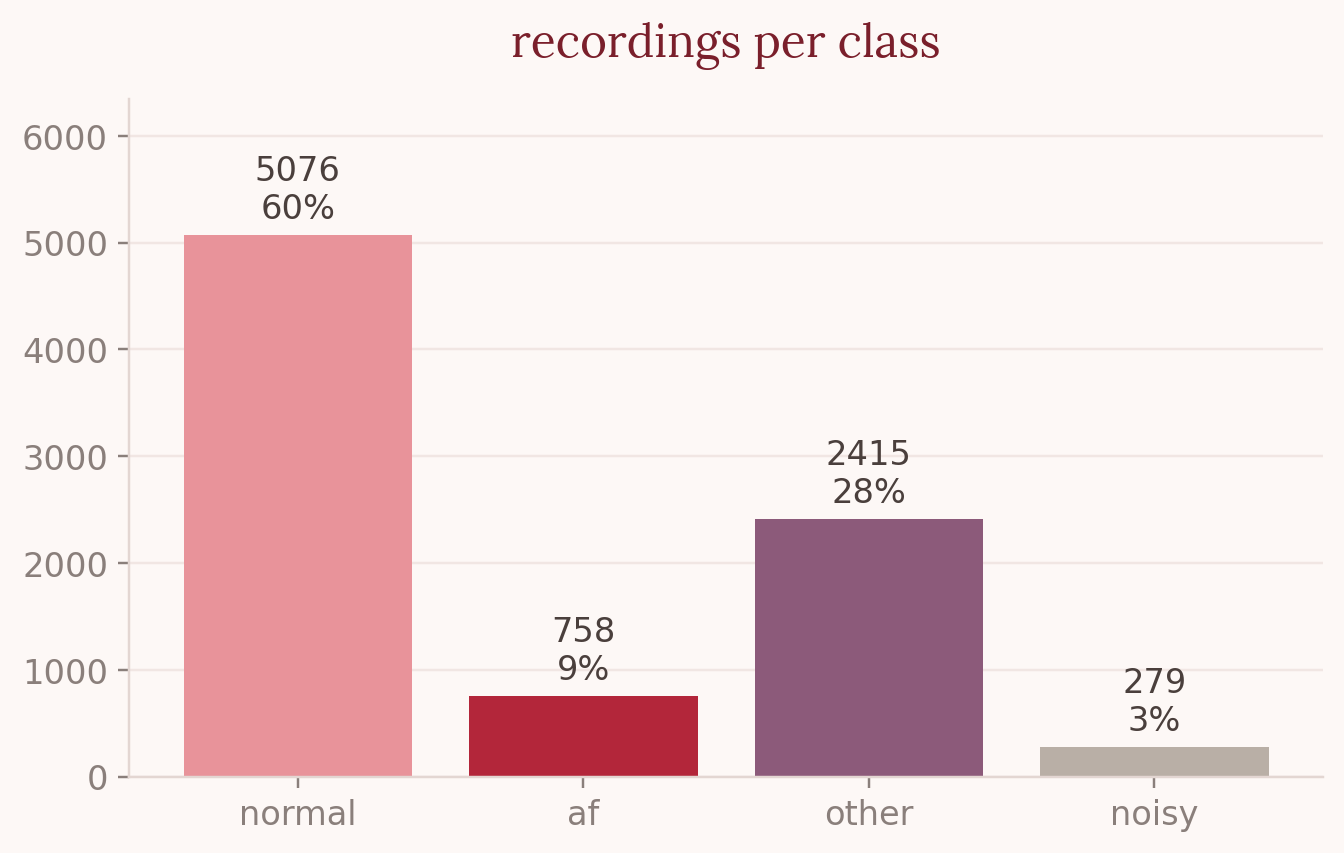

In [15]:
from scipy.io import loadmat

labels = pd.read_csv('REFERENCE-v3.csv', header=None, names=['record', 'label'])

def load_ecg(record):
    return loadmat(f'training2017/{record}.mat')['val'][0] / 1000.0  # mV

counts = labels.label.value_counts().reindex(['N', 'A', 'O', '~'])
plt.figure(figsize=(7, 4))
bars = plt.bar([NAMES[k] for k in counts.index], counts.values, color=[COLORS[k] for k in counts.index])
plt.bar_label(bars, [f'{v}\n{v/len(labels):.0%}' for v in counts.values], padding=3)
plt.ylim(0, counts.max() * 1.25)
plt.title('recordings per class'); plt.show()



---



## Features
Find each heartbeat, then measure how uneven the gaps between beats are. Cardiologists call AF "irregularly irregular", so that's the main clue. A few extra features help catch noisy recordings.

In [16]:
from scipy.signal import butter, filtfilt, find_peaks
from scipy.stats import kurtosis, skew

def bandpass(x, lo, hi, fs=FS, order=3):
    b, a = butter(order, [lo / (fs / 2), hi / (fs / 2)], btype='band')
    return filtfilt(b, a, x)

def detect_r_peaks(x, fs=FS):
    # pan-tompkins style, works on flipped ecgs too
    qrs = bandpass(x, 5, 15, fs)
    energy = np.gradient(qrs) ** 2
    win = int(0.12 * fs)
    energy = np.convolve(energy, np.ones(win) / win, mode='same')
    cand, _ = find_peaks(energy, height=0.3 * np.percentile(energy, 99), distance=int(0.25 * fs))
    # snap to the actual peak
    clean = bandpass(x, 0.5, 40, fs)
    half = int(0.075 * fs)
    peaks = [max(0, c - half) + np.argmax(np.abs(clean[max(0, c - half):c + half])) for c in cand]
    return np.unique(np.array(peaks, dtype=int))

def sample_entropy(x, m=2, r=0.2):
    x = np.asarray(x, dtype=float); n = len(x)
    if n < m + 3: return np.nan
    tol = r * x.std() if x.std() > 0 else 1e-6
    def count(mm):
        t = np.array([x[i:i + mm] for i in range(n - m)])
        d = np.max(np.abs(t[:, None, :] - t[None, :, :]), axis=2)
        return (np.sum(d <= tol) - len(t)) / 2
    b, a = count(m), count(m + 1)
    return np.log(n) if a == 0 or b == 0 else -np.log(a / b)

def extract_features(x, fs=FS):
    peaks = detect_r_peaks(x, fs)
    rr = np.diff(peaks) / fs
    f = {'n_beats': len(peaks)}
    if len(rr) >= 3:
        drr = np.diff(rr)
        f.update(mean_rr=rr.mean(), heart_rate=60 / rr.mean(), sdnn=rr.std(),
                 rmssd=np.sqrt(np.mean(drr ** 2)), pnn50=np.mean(np.abs(drr) > 0.05),
                 cv_rr=rr.std() / rr.mean(),
                 rr_range=(np.percentile(rr, 90) - np.percentile(rr, 10)) / rr.mean(),
                 turning_ratio=np.sum(drr[:-1] * drr[1:] < 0) / max(len(drr) - 1, 1),
                 sampen_rr=sample_entropy(rr / rr.mean()))
    # for the noisy class
    clean = bandpass(x, 0.5, 40, fs)
    f.update(noise_ratio=np.std(bandpass(x, 45, 0.45 * fs, fs)) / (np.std(clean) + 1e-9),
             kurt=kurtosis(clean), skewness=skew(clean),
             amp_iqr=np.subtract(*np.percentile(clean, [75, 25])))
    return f



---



## What the ECGs look like
Triangles are the beats my detector found.

Normal has even spacing and a small P wave before each spike.

AF has uneven spacing and no clear P waves.

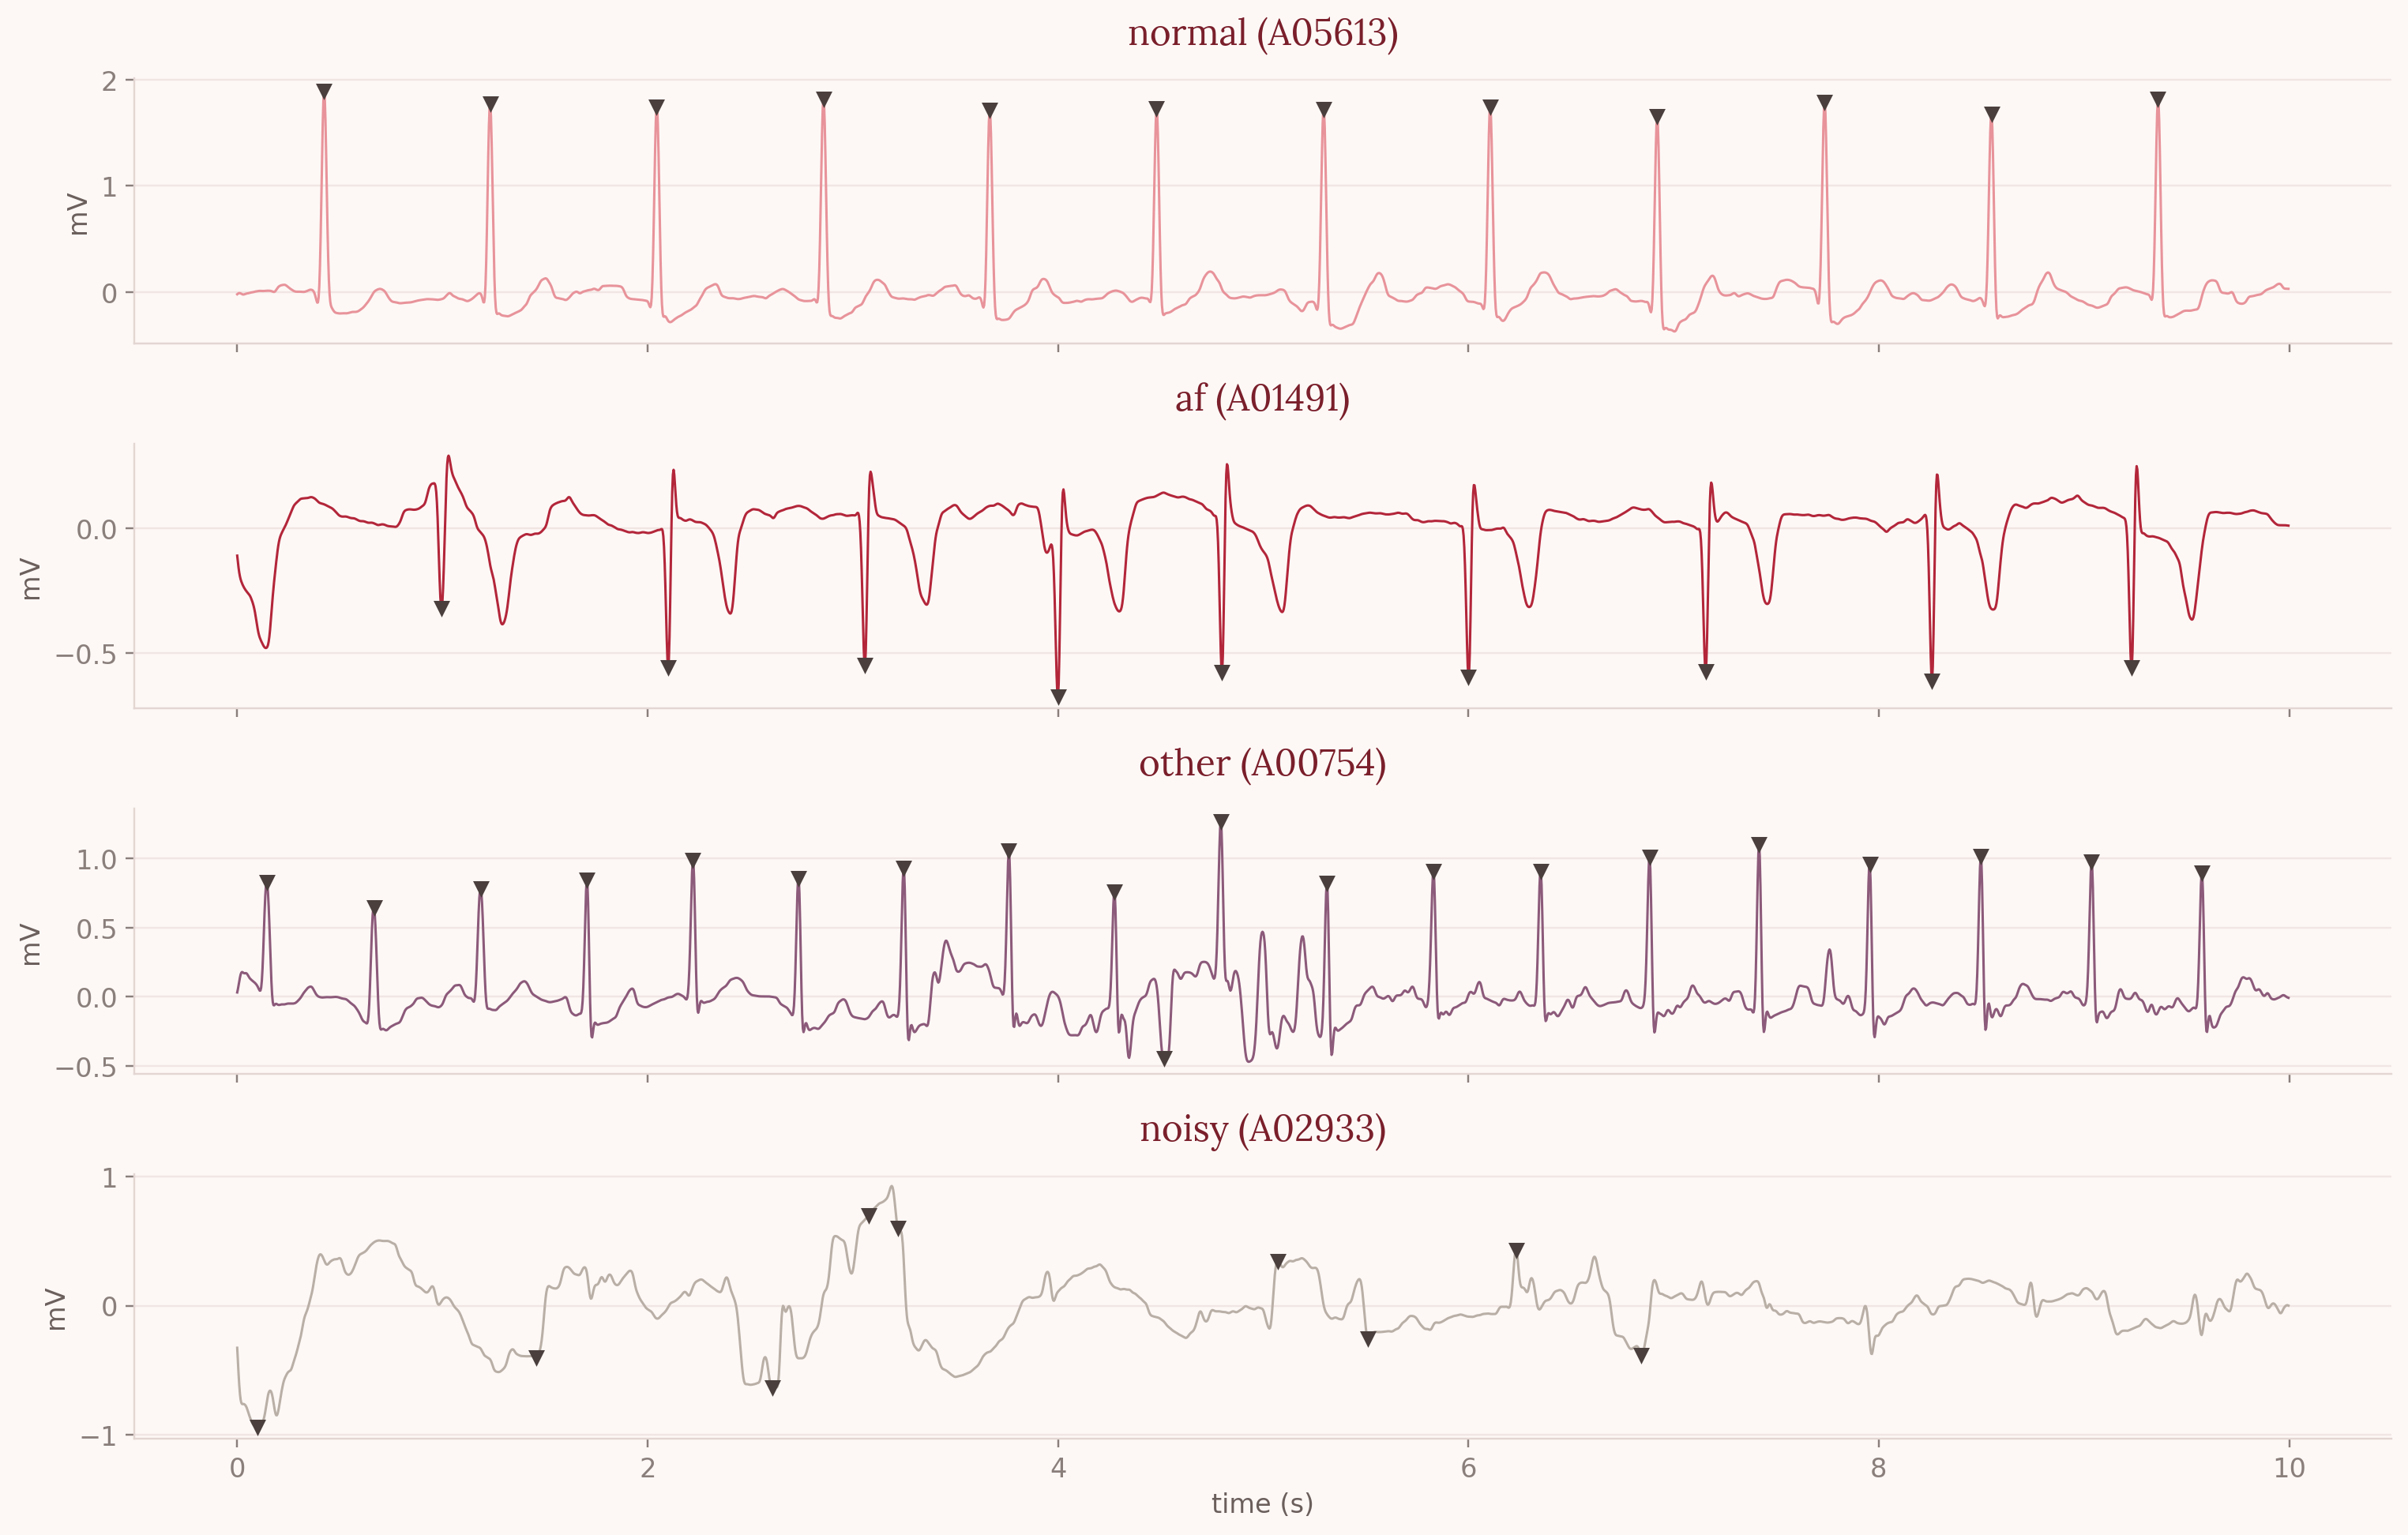

In [5]:
fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for ax, lab in zip(axes, ['N', 'A', 'O', '~']):
    rec = labels[labels.label == lab].record.sample(1).iloc[0]
    x = load_ecg(rec)[:10 * FS]
    clean, p = bandpass(x, 0.5, 40), detect_r_peaks(x)
    ax.plot(np.arange(len(x)) / FS, clean, color=COLORS[lab], lw=1)
    ax.plot(p / FS, clean[p], 'v', color='#4a3f3c', ms=5)
    ax.set_title(f'{NAMES[lab]} ({rec})'); ax.set_ylabel('mV')
axes[-1].set_xlabel('time (s)')
plt.tight_layout(); plt.show()



---



## RR intervals *(normal vs AF)*
AF beats come at random gaps whereas normal ones are even.

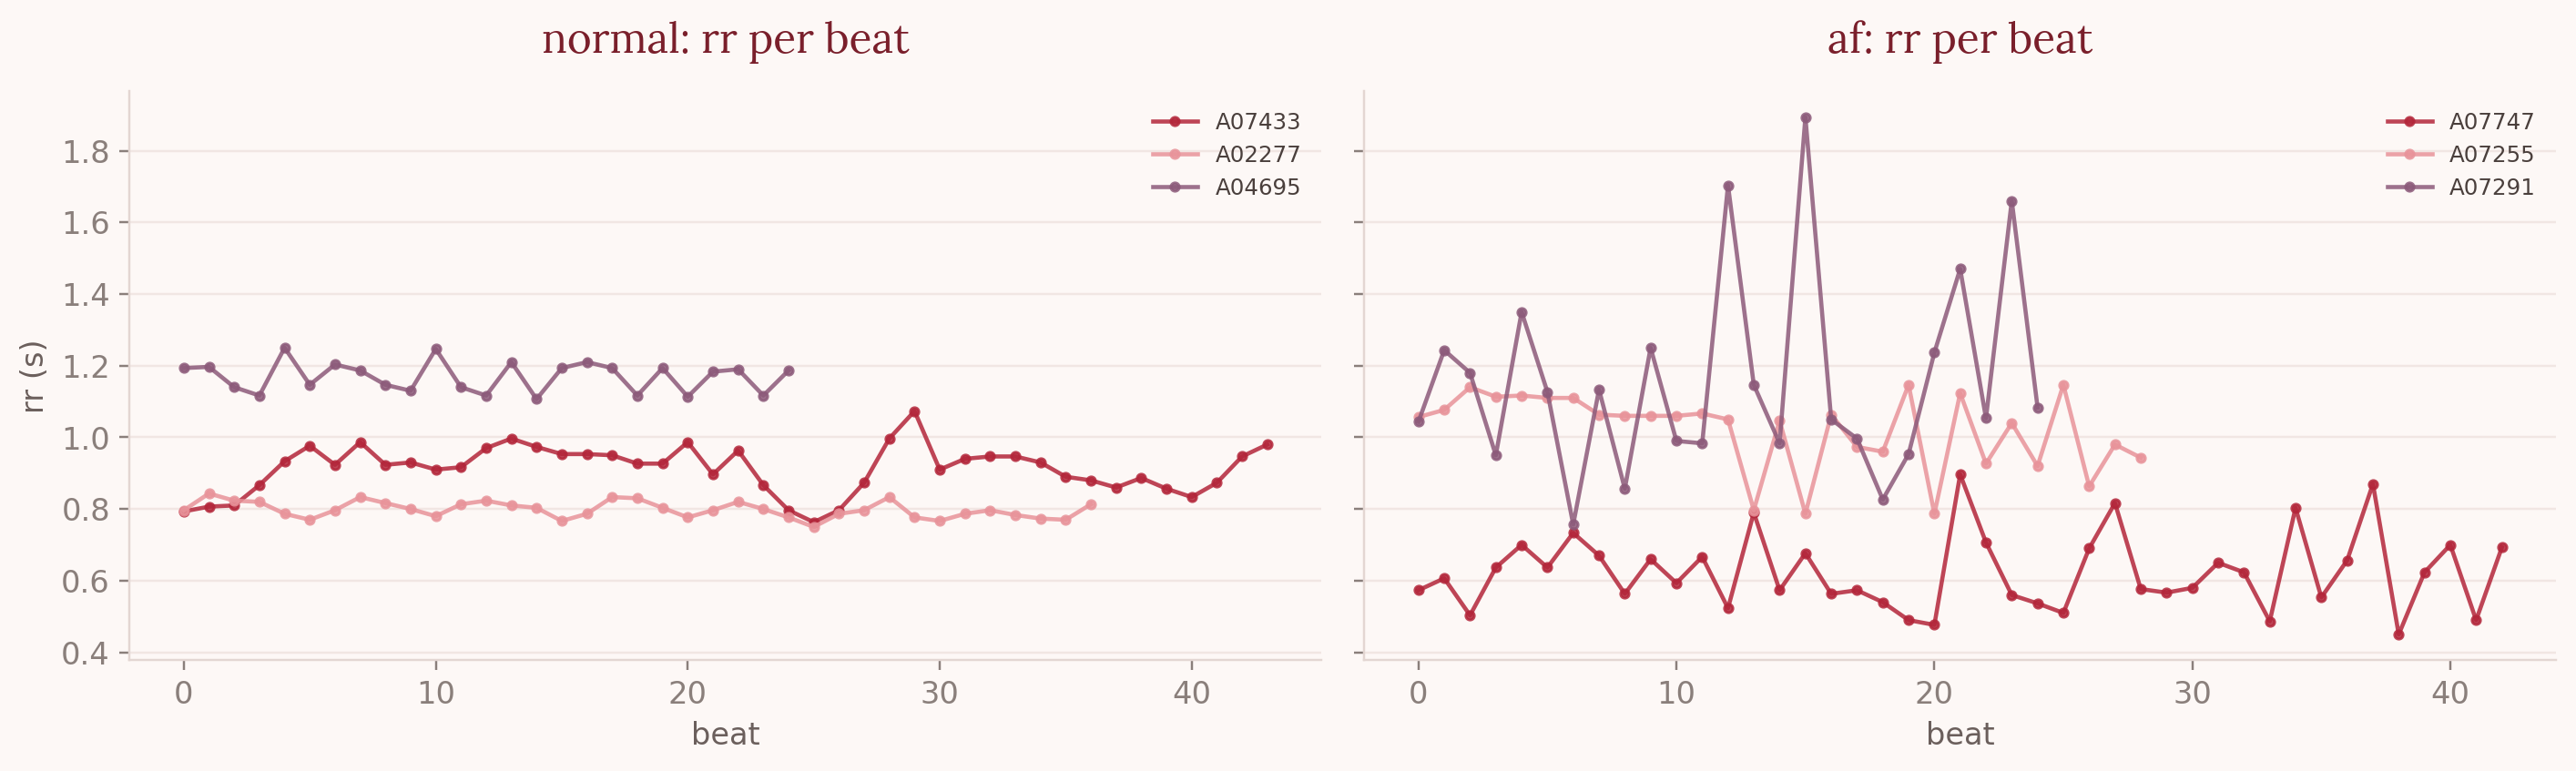

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, lab in zip(axes, ['N', 'A']):
    for rec in labels[labels.label == lab].record.sample(3, random_state=1):
        rr = np.diff(detect_r_peaks(load_ecg(rec))) / FS
        ax.plot(rr, '.-', alpha=0.85, label=rec)
    ax.set_title(f'{NAMES[lab]}: rr per beat'); ax.set_xlabel('beat'); ax.legend(fontsize=8)
axes[0].set_ylabel('rr (s)')
plt.tight_layout(); plt.show()



---



## Features for every recording

  0%|          | 0/8528 [00:00<?, ?it/s]

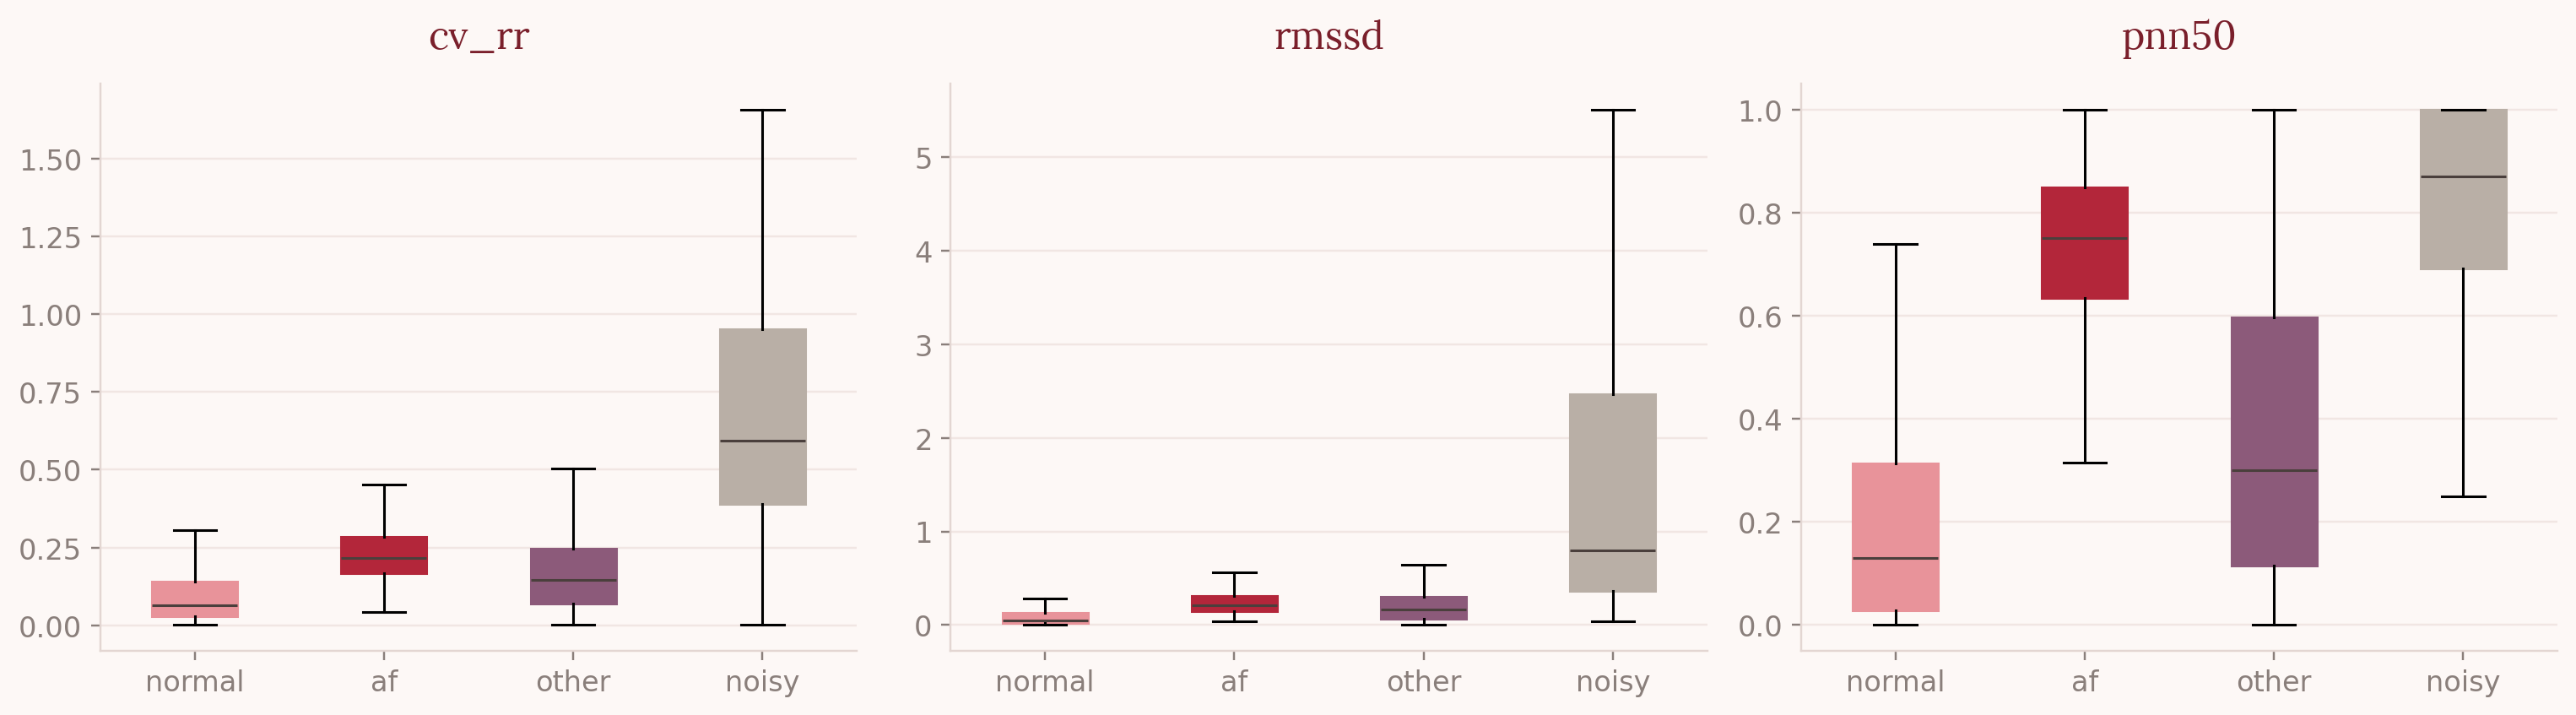

In [7]:
from tqdm.auto import tqdm
rows = [{**extract_features(load_ecg(r)), 'record': r} for r in tqdm(labels.record)]
feats = pd.DataFrame(rows).merge(labels, on='record')
feats.to_csv('features.csv', index=False)
FEATURES = [c for c in feats.columns if c not in ('record', 'label')]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['cv_rr', 'rmssd', 'pnn50']):
    data = [feats.loc[feats.label == l, col].dropna() for l in ['N', 'A', 'O', '~']]
    bp = ax.boxplot(data, tick_labels=list(NAMES.values()), showfliers=False, patch_artist=True,
                    medianprops={'color': '#4a3f3c'})
    for patch, l in zip(bp['boxes'], ['N', 'A', 'O', '~']):
        patch.set_facecolor(COLORS[l]); patch.set_edgecolor(COLORS[l])
    ax.set_title(col)
plt.tight_layout(); plt.show()



---



## Baseline models
Logistic regression vs gradient boosting, with 5-fold cross-validation so that every recording gets tested by a model that never saw it.

Challenge score = mean F1 of normal, AF and other

,f1 normal,f1 af,f1 other,f1 noisy,challenge score,af sensitivity,af specificity
logistic regression,0.737,0.625,0.485,0.419,0.616,0.806,0.924
gradient boosting,0.851,0.733,0.650,0.478,0.745,0.730,0.975


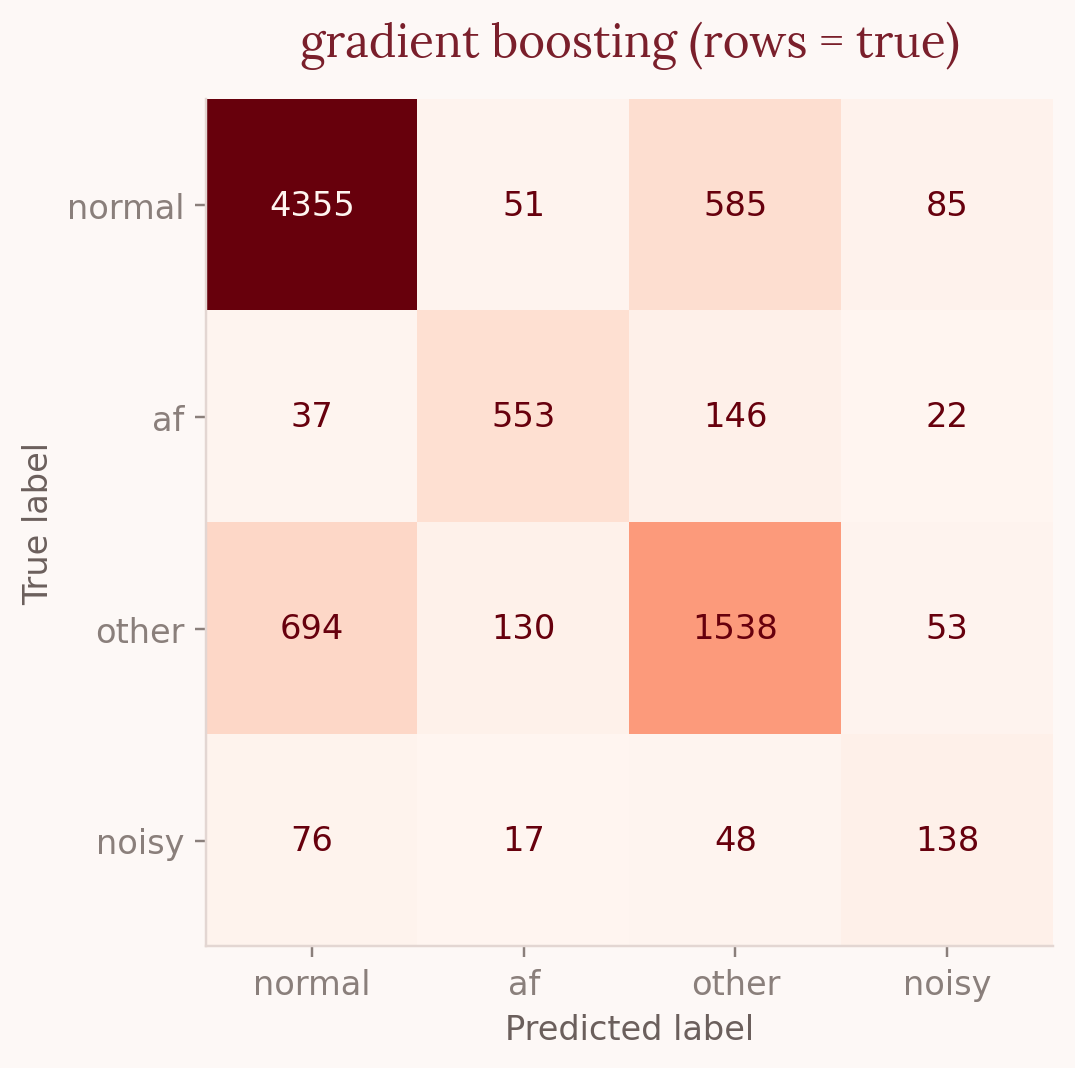

In [18]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, ConfusionMatrixDisplay

X, y = feats[FEATURES].replace([np.inf, -np.inf], np.nan), feats.label.values
cv = StratifiedKFold(5, shuffle=True, random_state=0)
models = {
    'logistic regression': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                         LogisticRegression(max_iter=2000, class_weight='balanced')),
    'gradient boosting': HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                        class_weight='balanced', random_state=0),
}
preds, results = {}, {}
for name, m in models.items():
    p = cross_val_predict(m, X, y, cv=cv); preds[name] = p
    f1 = f1_score(y, p, labels=['N', 'A', 'O', '~'], average=None)
    results[name] = {'f1 normal': f1[0], 'f1 af': f1[1], 'f1 other': f1[2], 'f1 noisy': f1[3],
                     'challenge score': f1[:3].mean(),
                     'af sensitivity': ((y == 'A') & (p == 'A')).sum() / (y == 'A').sum(),
                     'af specificity': ((y != 'A') & (p != 'A')).sum() / (y != 'A').sum()}
display(pd.DataFrame(results).T.style.format('{:.3f}').background_gradient(cmap='Reds', axis=None))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y, preds['gradient boosting'], labels=['N', 'A', 'O', '~'],
                                        display_labels=list(NAMES.values()), cmap='Reds',
                                        colorbar=False, ax=ax)
ax.grid(False); ax.set_title('gradient boosting (rows = true)'); plt.show()



---



## What the model relied on
Shuffled one feature at a time and observed how much the score drops.

If rhythm features come out on top, the model is using the same clue cardiologists use.

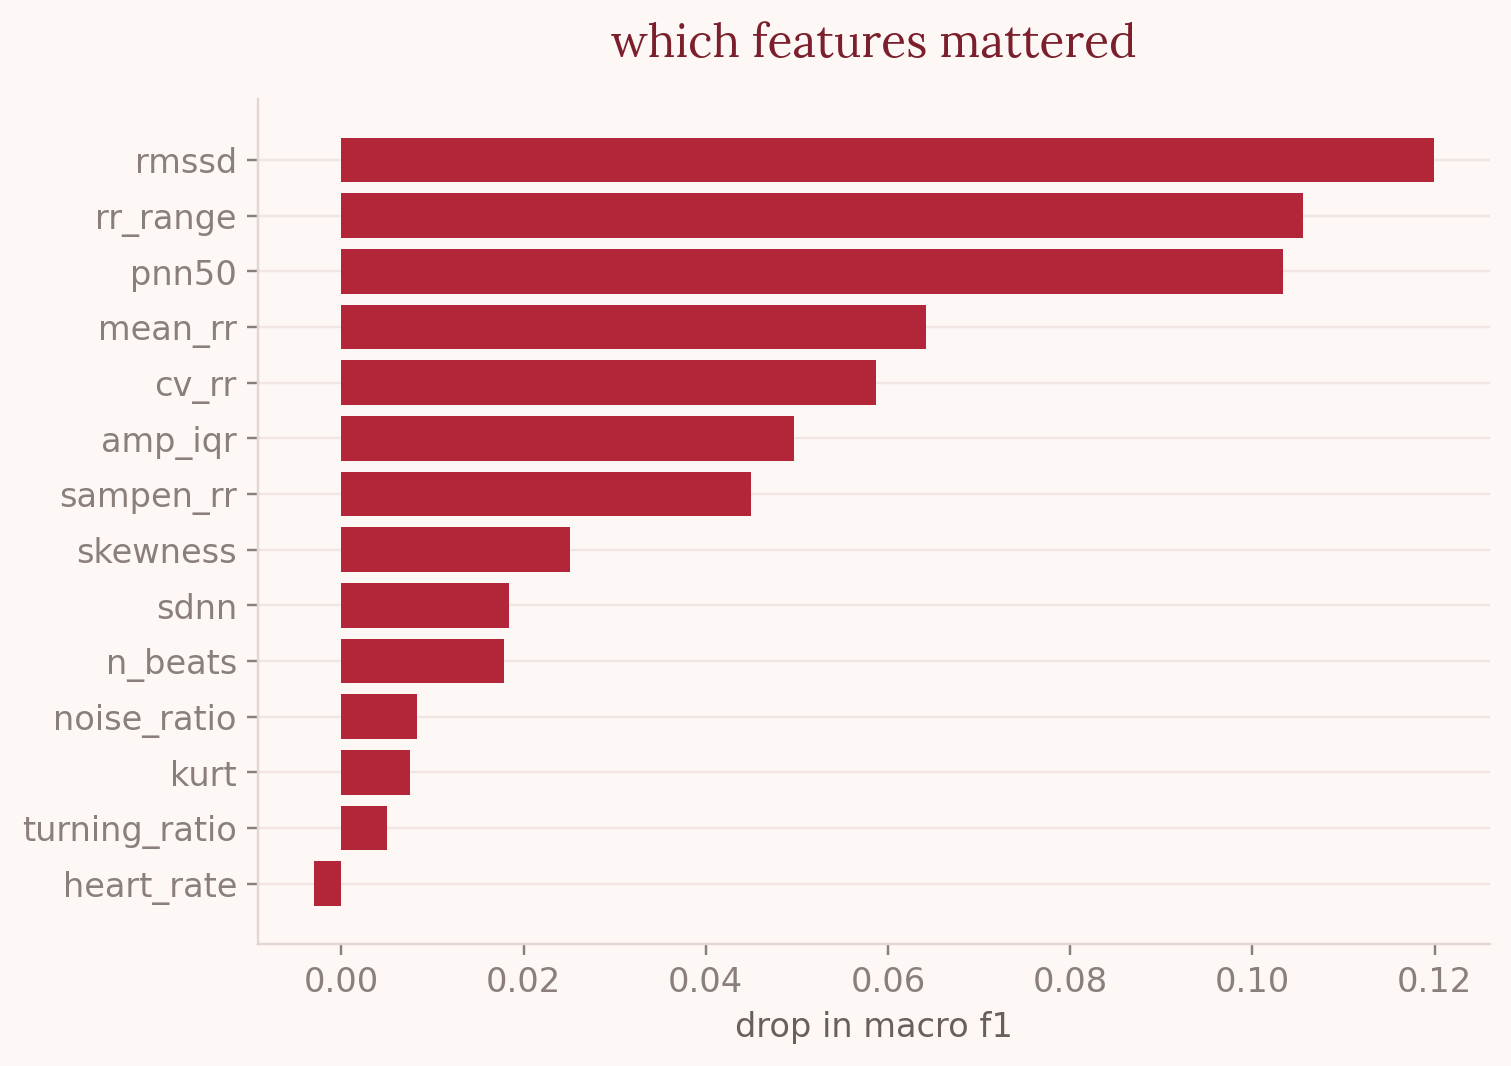

In [9]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
m = models['gradient boosting'].fit(Xtr, ytr)
imp = permutation_importance(m, Xte, yte, scoring='f1_macro', n_repeats=10, random_state=0)
o = np.argsort(imp.importances_mean)
plt.figure(figsize=(7, 5))
plt.barh(np.array(FEATURES)[o], imp.importances_mean[o], color=RED)
plt.xlabel('drop in macro f1'); plt.title('which features mattered')
plt.tight_layout(); plt.show()



---



## Where it fails
Which AF recordings it missed, and whether noise makes it worse.

missed af: 205 of 758
pred
other     146
normal     37
noisy      22
Name: count, dtype: int64
noise_level
lowest     0.600000
low        0.670807
high       0.818182
highest    0.784753
dtype: float64


/tmp/ipykernel_12353/4076071629.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(res[res.label == 'A'].groupby('noise_level', observed=True).apply(lambda d: (d.pred == 'A').mean()))


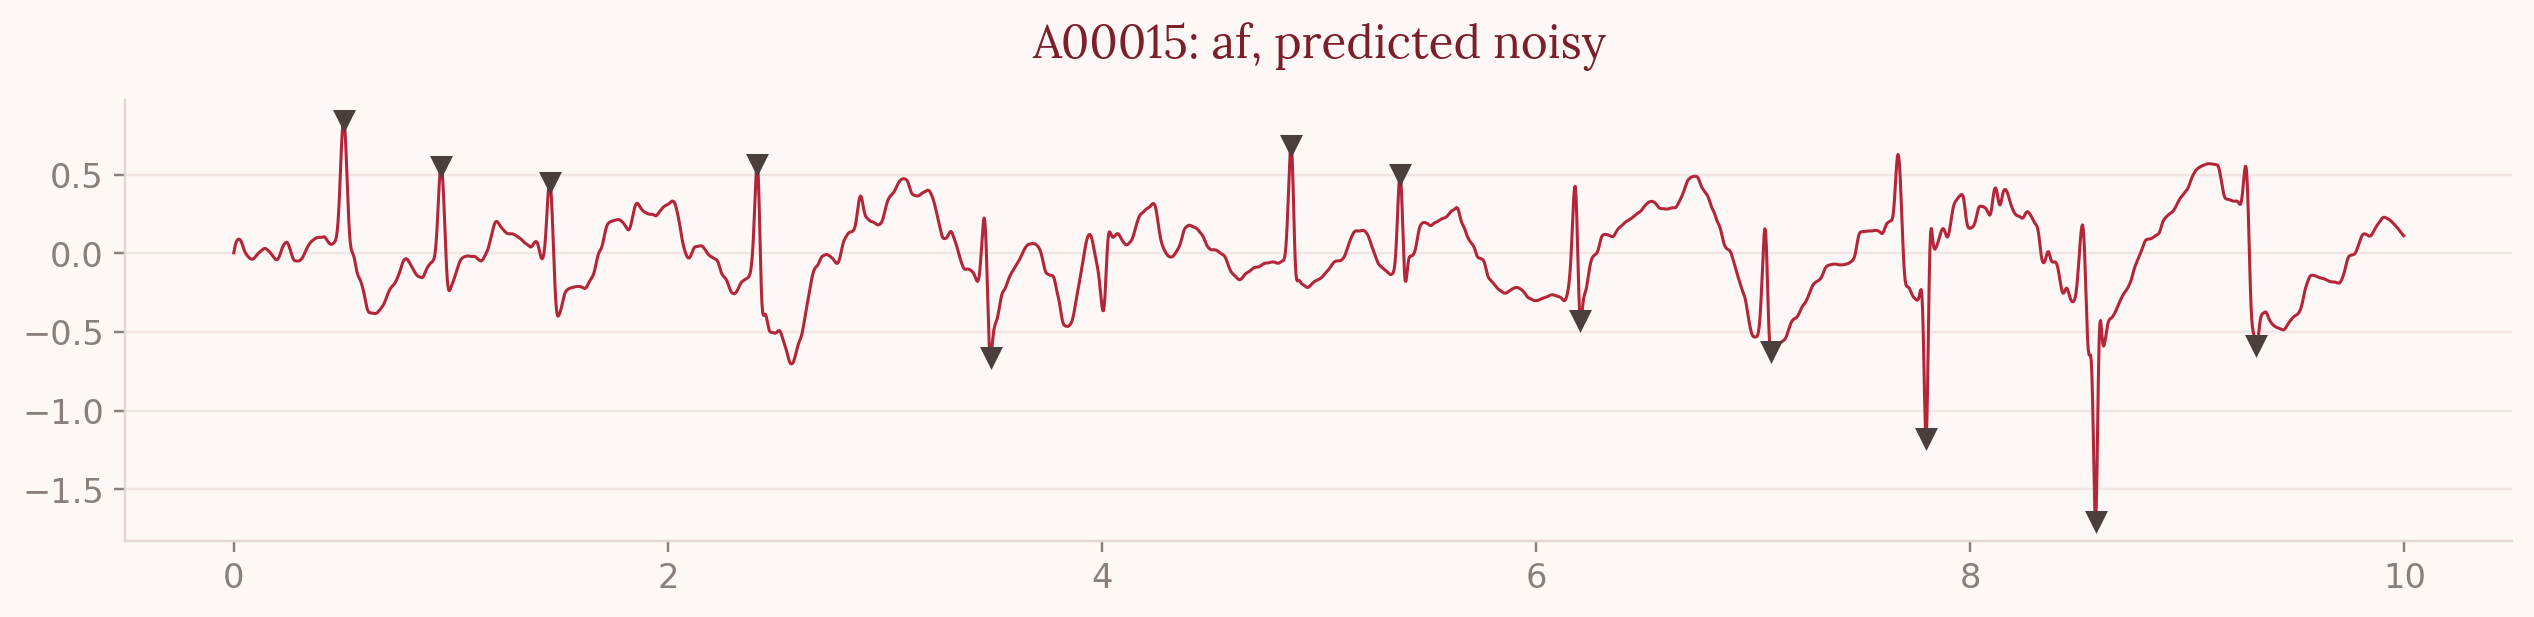

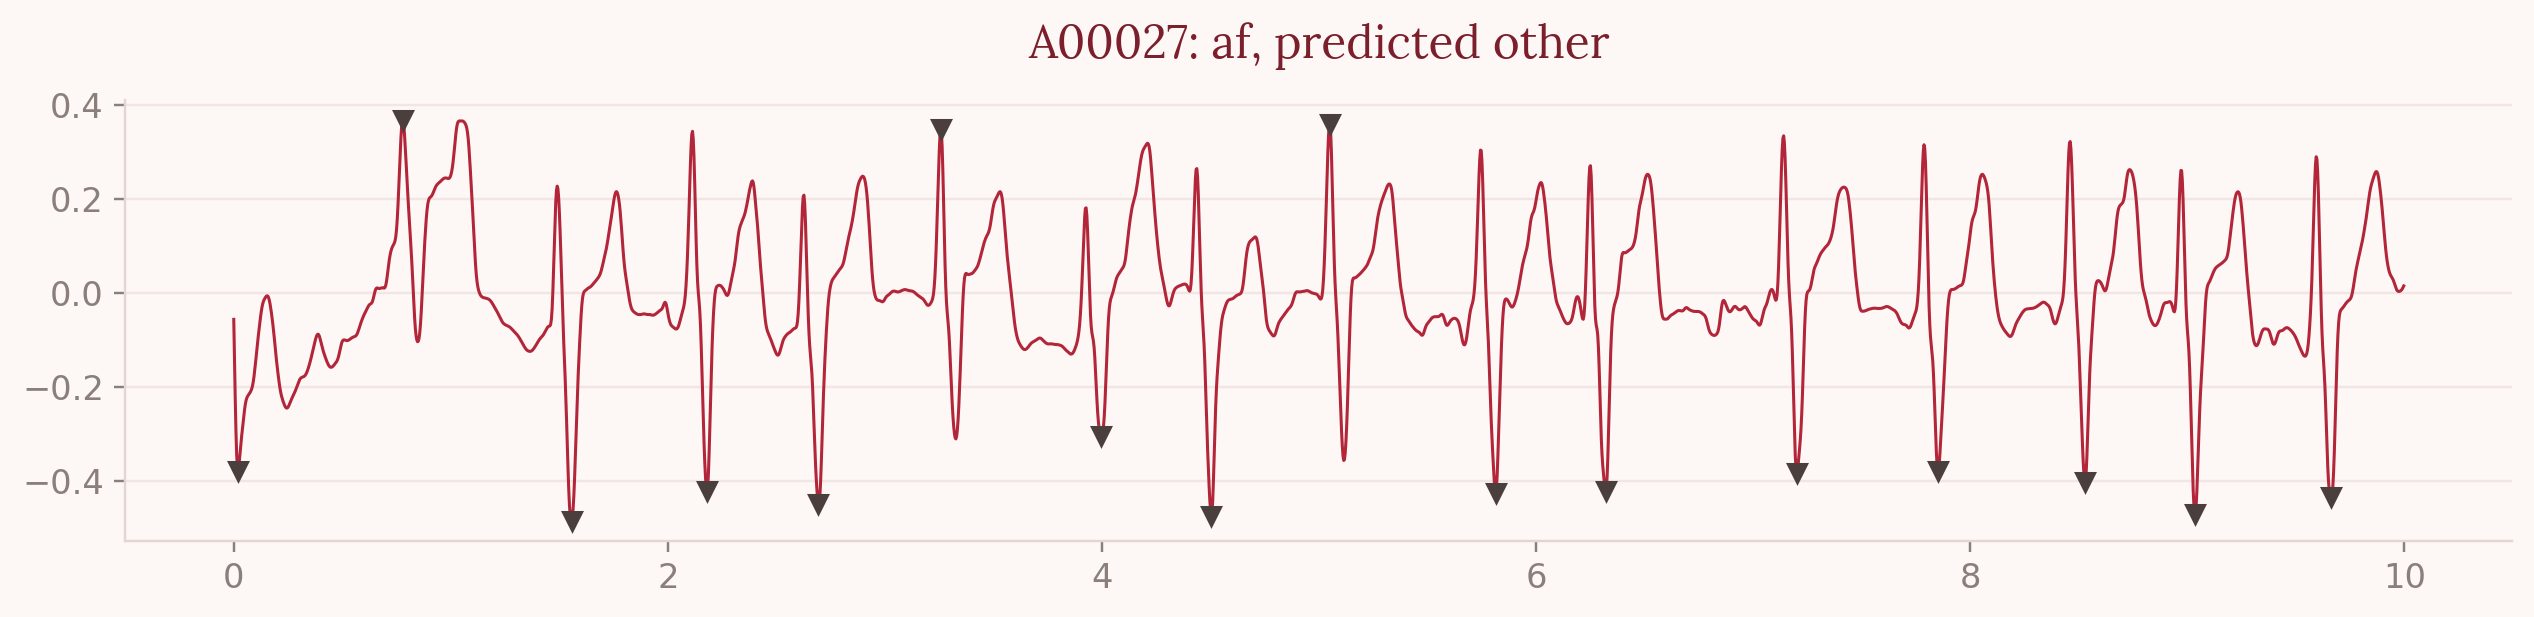

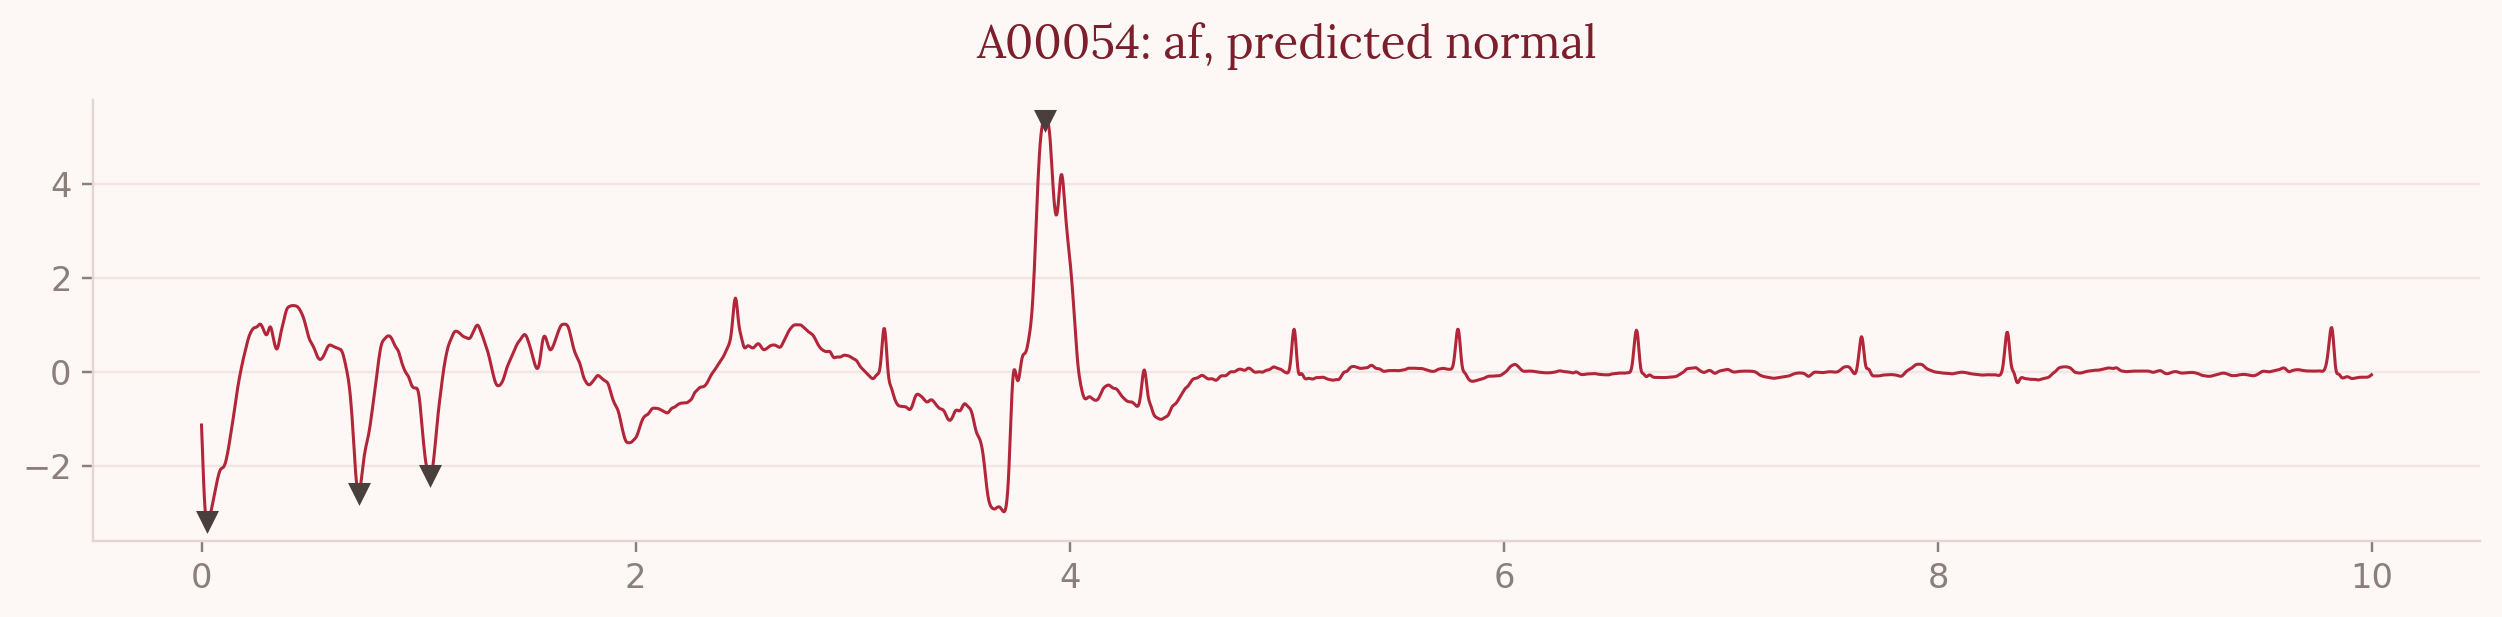

In [10]:
res = feats[['record', 'label', 'noise_ratio']].copy()
res['pred'] = preds['gradient boosting']
af = res[res.label == 'A']
print('missed af:', (af.pred != 'A').sum(), 'of', len(af))
print(af[af.pred != 'A'].pred.map(NAMES).value_counts())
res['noise_level'] = pd.qcut(res.noise_ratio, 4, labels=['lowest', 'low', 'high', 'highest'])
print(res[res.label == 'A'].groupby('noise_level', observed=True).apply(lambda d: (d.pred == 'A').mean()))

for _, r in af[af.pred != 'A'].head(3).iterrows():
    x = load_ecg(r.record)[:10 * FS]; clean, p = bandpass(x, 0.5, 40), detect_r_peaks(x)
    plt.figure(figsize=(14, 2.6))
    plt.plot(np.arange(len(x)) / FS, clean, color=RED, lw=1)
    plt.plot(p / FS, clean[p], 'v', color='#4a3f3c')
    plt.title(f'{r.record}: af, predicted {NAMES[r.pred]}'); plt.show()



---



## What I found
Gradient boosting scored 0.745. The best teams in 2017 got about 0.83, so I'm happy with that for a model that only looks at beat timing.

It caught 553 of 758 AF recordings (73%). When it missed AF it mostly guessed "other", and only 37 times "normal". On a watch an "other" result would still get checked, so those misses are not quite worrisome.

Logistic regression actually caught more AF (81%) but gave a significant number of false alarms. I'm not sure which one is better for a smartwatch. A false alarm costs someone a doctor's visit, whilst a missed AF could cost a stroke.

RMSSD, RR range and pNN50 were the top features. All of them measure how uneven the beats are, which is what cardiologists look for first in AF.

The "other" class was the weak spot. 694 of them got called normal. I think it's because "other" is a mix of lots of different rhythms.

A00015 is AF but got called noisy. The baseline drifts and some spikes point down, and the detector marked a few wrong points. If the beats are wrong, every feature built on them is wrong too. Beat timing also can't show P waves, so in part 2 I'm training a CNN on the raw ECG.

---

